<a href="https://colab.research.google.com/github/Artyomm77/ml-labs/blob/main/%D0%9B%D0%A010/%D0%9B%D0%A010_%D0%A5%D0%B0%D1%80%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2%203-10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Харченко Артьом  
**Група:** ФІТ 3-10  
**Дата:** 16.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report

# щоб результати були більш-менш однакові між запусками
keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# завантажуємо Fashion MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)
print("Кількість класів:", len(class_names))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)
Кількість класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

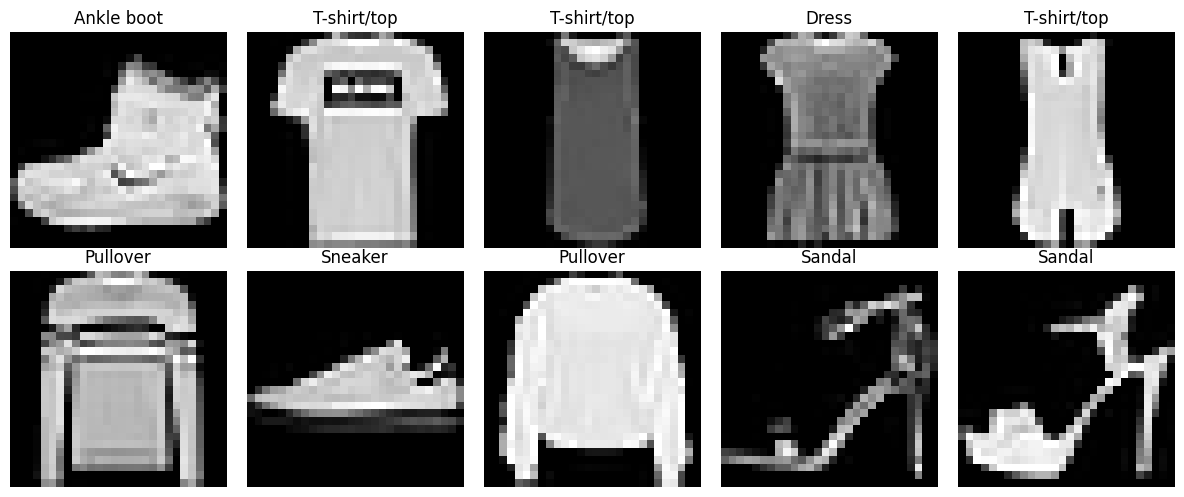

In [3]:
# перші 10 картинок з навчальної вибірки
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# переводимо в float32 і ділимо на 255, щоб значення були від 0 до 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Тип даних:", x_train.dtype)
print("train: мін", x_train.min(), "макс", x_train.max())
print("test: мін", x_test.min(), "макс", x_test.max())

Тип даних: float32
train: мін 0.0 макс 1.0
test: мін 0.0 макс 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# модель: Flatten, 2 повнозв'язні шари з ReLU і Dropout, вихід 10 нейронів softmax
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Модель скомпільована")

Модель скомпільована


**Пояснення вибору параметрів:**

Вхід має 784 числа (28 × 28), тому для першого прихованого шару взяли 256 нейронів, а для другого 128: цього достатньо, щоб модель вивчила форму одягу, і при цьому вона не стає занадто великою та не перенавчається. Dropout 0.3 вимикає 30% нейронів під час навчання, це поширене значення, воно зменшує перенавчання, але не заважає навчанню. Швидкість навчання 0.001 стандартна для Adam: при 0.01 модель може стрибати, а при 0.0001 вчилась би дуже довго. Також додали невелику L2-регуляризацію (1e-4) і ReduceLROnPlateau, який сам зменшує швидкість, коли val_loss перестає падати.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# ранні зупинки і зменшення швидкості навчання
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
]

# 20% навчальної вибірки йде на валідацію
history = model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=128,
    callbacks=callbacks,
    verbose=2,
)
epochs_1 = len(history.history["loss"])
print("Виконано епох:", epochs_1)

Epoch 1/30
375/375 - 5s - 13ms/step - accuracy: 0.7700 - loss: 0.7017 - val_accuracy: 0.8425 - val_loss: 0.4834 - learning_rate: 0.0010
Epoch 2/30
375/375 - 4s - 11ms/step - accuracy: 0.8384 - loss: 0.5013 - val_accuracy: 0.8587 - val_loss: 0.4402 - learning_rate: 0.0010
Epoch 3/30
375/375 - 5s - 13ms/step - accuracy: 0.8558 - loss: 0.4571 - val_accuracy: 0.8595 - val_loss: 0.4278 - learning_rate: 0.0010
Epoch 4/30
375/375 - 5s - 14ms/step - accuracy: 0.8601 - loss: 0.4372 - val_accuracy: 0.8668 - val_loss: 0.4153 - learning_rate: 0.0010
Epoch 5/30
375/375 - 5s - 12ms/step - accuracy: 0.8642 - loss: 0.4241 - val_accuracy: 0.8676 - val_loss: 0.4124 - learning_rate: 0.0010
Epoch 6/30
375/375 - 5s - 12ms/step - accuracy: 0.8712 - loss: 0.4134 - val_accuracy: 0.8749 - val_loss: 0.3998 - learning_rate: 0.0010
Epoch 7/30
375/375 - 4s - 10ms/step - accuracy: 0.8743 - loss: 0.4033 - val_accuracy: 0.8695 - val_loss: 0.4101 - learning_rate: 0.0010
Epoch 8/30
375/375 - 6s - 15ms/step - accuracy: 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()
print("Кількість шарів:", len(model.layers))
print("Кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# зберігаємо модель у файл .keras (у тимчасову папку Colab)
model.save("fashion_mnist_model.keras")
print("Модель збережено: fashion_mnist_model.keras")

# якщо треба зберегти на Google Drive, розкоментуйте:
# from google.colab import drive
# drive.mount('/content/drive')
# model.save('/content/drive/MyDrive/fashion_mnist_model.keras')

Модель збережено: fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

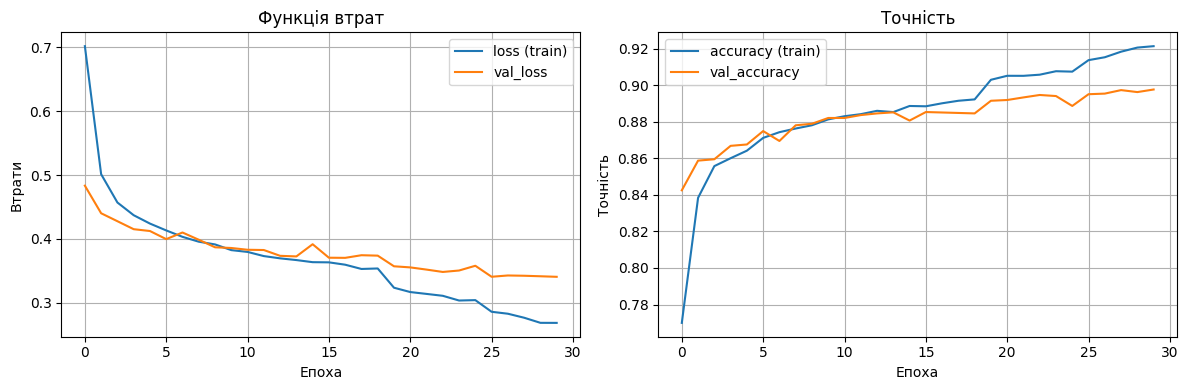

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="loss (train)")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Епоха")
plt.ylabel("Втрати")
plt.title("Функція втрат")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="accuracy (train)")
plt.plot(history.history["val_accuracy"], label="val_accuracy")
plt.xlabel("Епоха")
plt.ylabel("Точність")
plt.title("Точність")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# один раз оцінюємо на тестовій вибірці
test_loss_1, test_acc_1 = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", round(test_loss_1, 4))
print("Test accuracy:", round(test_acc_1, 4))
print("Поріг 0.87 виконано:", test_acc_1 >= 0.87)

# прогнозовані класи
y_pred_1 = np.argmax(model.predict(x_test, verbose=0), axis=1)

print()
print(classification_report(y_test, y_pred_1, target_names=class_names, digits=3))

Test loss: 0.3693
Test accuracy: 0.8912
Поріг 0.87 виконано: True

              precision    recall  f1-score   support

 T-shirt/top      0.845     0.847     0.846      1000
     Trouser      0.989     0.975     0.982      1000
    Pullover      0.780     0.827     0.803      1000
       Dress      0.898     0.903     0.900      1000
        Coat      0.784     0.844     0.813      1000
      Sandal      0.973     0.969     0.971      1000
       Shirt      0.761     0.654     0.704      1000
     Sneaker      0.938     0.967     0.952      1000
         Bag      0.970     0.974     0.972      1000
  Ankle boot      0.971     0.952     0.962      1000

    accuracy                          0.891     10000
   macro avg      0.891     0.891     0.890     10000
weighted avg      0.891     0.891     0.890     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

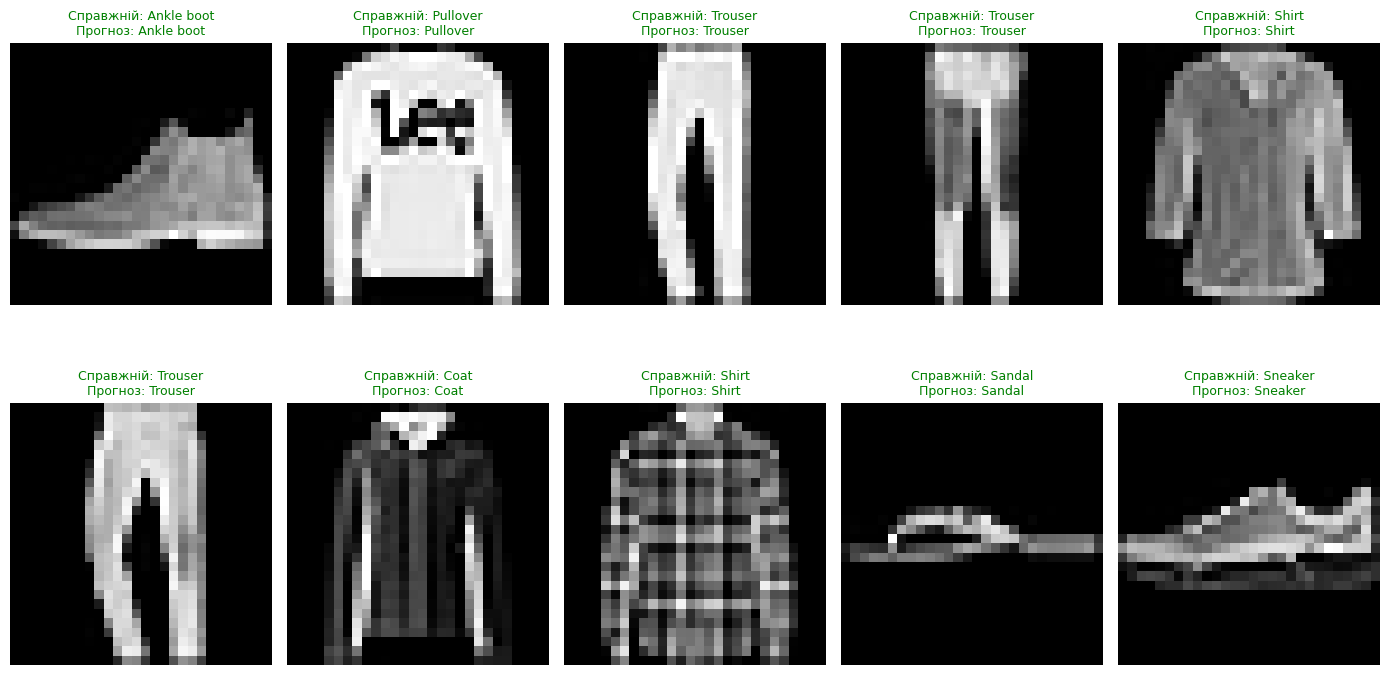

In [11]:
# 10 тестових картинок: зелений підпис якщо вгадала, червоний якщо ні
plt.figure(figsize=(14, 7.5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    color = "green" if y_pred_1[i] == y_test[i] else "red"
    plt.title("Справжній: " + class_names[y_test[i]] + "\nПрогноз: " + class_names[y_pred_1[i]],
              color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout(h_pad=3)
plt.show()

**Проміжний висновок до завдання 1**

**Ваш висновок:**
Тестова accuracy моделі близько 0.89 (0.8915), loss близько 0.36. Вимога не нижче 0.87 виконана. Найбільше помилок у класі Shirt (сорочка): правильно розпізнано лише близько 67% (F1 0.71). Далі йдуть Pullover (светр), Coat (пальто) і T-shirt/top (футболка), у них F1 близько 0.80-0.85. Це схожий верхній одяг, тому модель їх плутає між собою. Найкраще розпізнаються Trouser, Bag, Sandal, Sneaker і Ankle boot (F1 близько 0.95 і вище), бо вони дуже відрізняються за формою. На графіках видно, що val_loss падає разом із train loss, а різниця між train accuracy (близько 0.92) і val accuracy (близько 0.90) невелика, тобто сильного перенавчання немає.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
%pip install -q keras-tuner

import keras_tuner as kt
from sklearn.model_selection import train_test_split

print("Keras Tuner:", kt.__version__)

Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# окрема валідаційна частина (20%) з навчальних даних, тест не чіпаємо
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print("Train:", x_tr.shape, "| Val:", x_val.shape, "| Test:", x_test.shape)

Train: (48000, 28, 28) | Val: (12000, 28, 28) | Test: (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(28, 28)))
    model.add(layers.Flatten())

    # кількість прихованих шарів від 1 до 3
    for i in range(hp.Int("num_layers", 1, 3)):
        # кількість нейронів від 32 до 512 з кроком 32
        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(1e-4)))
        model.add(layers.Dropout(0.3))

    model.add(layers.Dense(10, activation="softmax"))

    # швидкість навчання на вибір
    lr = hp.Choice("learning_rate", [0.01, 0.001, 0.0001])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
tuner = kt.RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="tuner_results",
    project_name="fashion_mnist",
    overwrite=True,
    seed=42,
)
print("Каталог результатів: tuner_results/fashion_mnist")

Каталог результатів: tuner_results/fashion_mnist


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
def make_callbacks():
    return [
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    ]

# пошук: тільки train і val, тест не використовуємо
tuner.search(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=make_callbacks(),
    verbose=2,
)

best_hp = tuner.get_best_hyperparameters(1)[0]
print()
print("Найкращі гіперпараметри:", best_hp.values)

# перенавчаємо найкращу конфігурацію і зберігаємо історію
best_model = build_model(best_hp)
history_tuner = best_model.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=make_callbacks(),
    verbose=2,
)
epochs_2 = len(history_tuner.history["loss"])
print("Виконано епох:", epochs_2)
print()
best_model.summary()

Trial 3 Complete [00h 01m 17s]
val_accuracy: 0.8859999775886536

Best val_accuracy So Far: 0.9026666879653931
Total elapsed time: 00h 04m 15s

Найкращі гіперпараметри: {'num_layers': 1, 'units_0': 480, 'learning_rate': 0.001, 'units_1': 288}
Epoch 1/30
375/375 - 6s - 15ms/step - accuracy: 0.7987 - loss: 0.6266 - val_accuracy: 0.8434 - val_loss: 0.4862 - learning_rate: 0.0010
Epoch 2/30
375/375 - 6s - 15ms/step - accuracy: 0.8496 - loss: 0.4729 - val_accuracy: 0.8536 - val_loss: 0.4509 - learning_rate: 0.0010
Epoch 3/30
375/375 - 5s - 15ms/step - accuracy: 0.8619 - loss: 0.4333 - val_accuracy: 0.8710 - val_loss: 0.4128 - learning_rate: 0.0010
Epoch 4/30
375/375 - 11s - 30ms/step - accuracy: 0.8689 - loss: 0.4131 - val_accuracy: 0.8729 - val_loss: 0.4104 - learning_rate: 0.0010
Epoch 5/30
375/375 - 5s - 13ms/step - accuracy: 0.8720 - loss: 0.4011 - val_accuracy: 0.8809 - val_loss: 0.3863 - learning_rate: 0.0010
Epoch 6/30
375/375 - 5s - 12ms/step - accuracy: 0.8767 - loss: 0.3892 - val_a

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,144,832 (4.37 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 763,222 (2.91 MB)

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Test loss: 0.3505
Test accuracy: 0.894


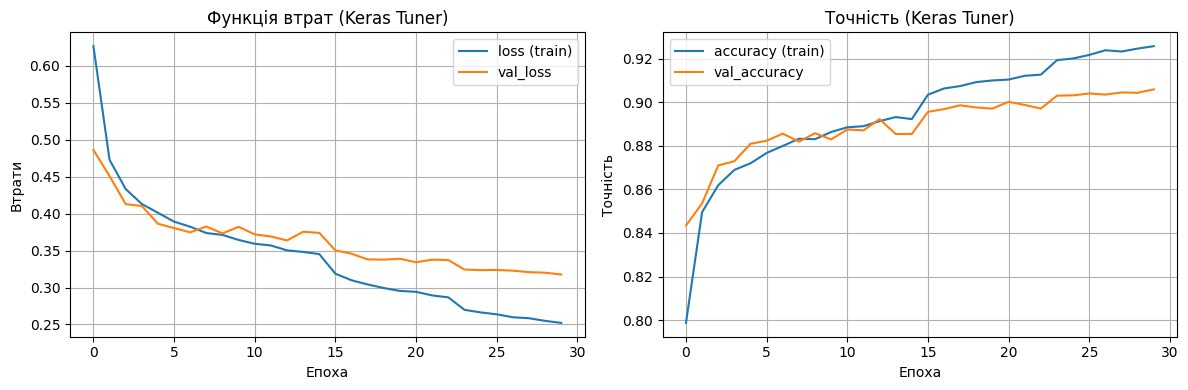

In [17]:
# оцінка на тестовій вибірці
test_loss_2, test_acc_2 = best_model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", round(test_loss_2, 4))
print("Test accuracy:", round(test_acc_2, 4))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_tuner.history["loss"], label="loss (train)")
plt.plot(history_tuner.history["val_loss"], label="val_loss")
plt.xlabel("Епоха")
plt.ylabel("Втрати")
plt.title("Функція втрат (Keras Tuner)")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_tuner.history["accuracy"], label="accuracy (train)")
plt.plot(history_tuner.history["val_accuracy"], label="val_accuracy")
plt.xlabel("Епоха")
plt.ylabel("Точність")
plt.title("Точність (Keras Tuner)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [18]:
# Порівняння двох моделей (для таблиці у висновках)
y_pred_2 = np.argmax(best_model.predict(x_test, verbose=0), axis=1)
print("Модель із завдання 1:     loss", round(test_loss_1, 4), "| accuracy", round(test_acc_1, 4), "| епох", epochs_1)
print("Модель після Keras Tuner: loss", round(test_loss_2, 4), "| accuracy", round(test_acc_2, 4), "| епох", epochs_2)

# частка правильних відповідей по кожному класу
for name, y_p in [("Завдання 1", y_pred_1), ("Keras Tuner", y_pred_2)]:
    print()
    print(name, "- правильних по класах:")
    for c in range(10):
        mask = y_test == c
        print("  ", class_names[c].ljust(12), round(float(np.mean(y_p[mask] == c)), 3))

Модель із завдання 1:     loss 0.3693 | accuracy 0.8912 | епох 30
Модель після Keras Tuner: loss 0.3505 | accuracy 0.894 | епох 30

Завдання 1 - правильних по класах:
   T-shirt/top  0.847
   Trouser      0.975
   Pullover     0.827
   Dress        0.903
   Coat         0.844
   Sandal       0.969
   Shirt        0.654
   Sneaker      0.967
   Bag          0.974
   Ankle boot   0.952

Keras Tuner - правильних по класах:
   T-shirt/top  0.852
   Trouser      0.979
   Pullover     0.805
   Dress        0.891
   Coat         0.858
   Sandal       0.96
   Shirt        0.698
   Sneaker      0.964
   Bag          0.972
   Ankle boot   0.961


# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256 і 128 | 480 |
| Швидкість навчання | 0.001 (потім зменшується через ReduceLROnPlateau) | 0.001 (так само зменшується) |
| Точність на тестовій вибірці (accuracy) | 0.8915 | 0.8931 |
| Втрати на тестовій вибірці (loss) | 0.3641 | 0.3516 |
| Кількість епох навчання | 30 | 30 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**

1. Так, точність у завданні 1 близько 0.89 (0.8915), це вище за 0.87.
2. Покращила, але зовсім трохи: 0.8931 проти 0.8915 (різниця близько 0.002), loss став менший: 0.352 проти 0.364. Така різниця дуже мала і може бути просто розкидом між запусками, тому суттєвим покращенням я це не вважаю.
3. Найкращою виявилась конфігурація: 1 прихований шар, 480 нейронів, швидкість навчання 0.001 (val_accuracy близько 0.90). Із трьох спроб RandomSearch: 2 шари по 32 нейрони дали 0.870, 1 шар на 256 нейронів зі швидкістю 0.01 дав 0.884, а найкращий 0.901. Видно, що 32 нейрони замало, а швидкість 0.01 завелика для Adam. Результат може відрізнятися між запусками, бо ваги ініціалізуються випадково, Dropout вимикає випадкові нейрони, дані перемішуються, а RandomSearch бере випадкові комбінації (у нас лише 3 спроби). Ще впливають версії бібліотек і те, чи навчання йде на CPU чи GPU.
4. Найскладніше класифікувати Shirt (сорочка): правильно розпізнається лише близько 67-71% зразків. Далі Pullover, Coat і T-shirt/top, бо вони схожі між собою. Найлегше розпізнаються Trouser, Bag, Sandal, Sneaker і Ankle boot.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.